<a target="_blank" href="https://colab.research.google.com/github/tabt/geo_notebooks/blob/main/hex_relief_map.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Hex relief map with rayshader

Input: the coordinates of the map center (lon/lat, WGS84).

Pipeline:
1. Build a square area around the center in a local azimuthal equidistant projection (no distortion near the center).
2. Download a DEM via `elevatr` (AWS Terrain Tiles) and resample it onto a square metric grid.
3. Shade it as in the rayshader docs: `sphere_shade` + `ray_shade` + `ambient_shade`.
4. `plot_3d(..., baseshape = 'hex')`: rayshader cuts the hexagon from the square itself.
5. `render_snapshot()` / optional `render_highquality()`.

## Install libraries

In [ ]:
system('sudo apt-get install -y r-cran-rayshader')
system('sudo apt-get install -y r-cran-rayrender')
system('sudo apt-get install -y r-cran-elevatr')
system('sudo apt-get install -y r-cran-terra')
system('sudo apt-get install -y r-cran-sf')
system('sudo apt-get install -y r-cran-raster')
system('sudo apt-get install -y r-cran-irdisplay')

In [ ]:
options(rgl.useNULL = TRUE)   # off-screen rgl, needed in Jupyter / on a server
options(repr.plot.width = 8, repr.plot.height = 8)

library(rayshader)
library(elevatr)
library(terra)
library(sf)

elevatr v0.99.0 NOTE: Version 0.99.0 of 'elevatr' uses 'sf' and 'terra'.  Use 
of the 'sp', 'raster', and underlying 'rgdal' packages by 'elevatr' is being 
deprecated; however, get_elev_raster continues to return a RasterLayer.  This 
will be dropped in future versions, so please plan accordingly.

terra 1.9.50

Linking to GEOS 3.12.1, GDAL 3.8.4, PROJ 9.4.0; sf_use_s2() is TRUE



## Parameters

In [ ]:
# --- hex center (WGS84) ---
center_lon <- 160.26230982370132
center_lat <- 54.80664118556672

# --- extent ---
half_size_km <- 24    # half the side of the square around the center; the hex is cut from it

# --- data & quality ---
dem_zoom     <- 10    # elevatr zoom (8-12 typical; higher = finer & slower)
target_px    <- 800   # matrix size (higher = more detail, slower)
exaggeration <- 3   # vertical exaggeration

# --- camera ---
theta <- -45
phi   <- 45
zoom  <- 0.6

# --- output ---
out_snapshot    <- 'hex_relief_snapshot.png'
do_highquality  <- TRUE   # path-traced render (slow)
out_highquality <- 'hex_relief_hq.png'

## Area around the center

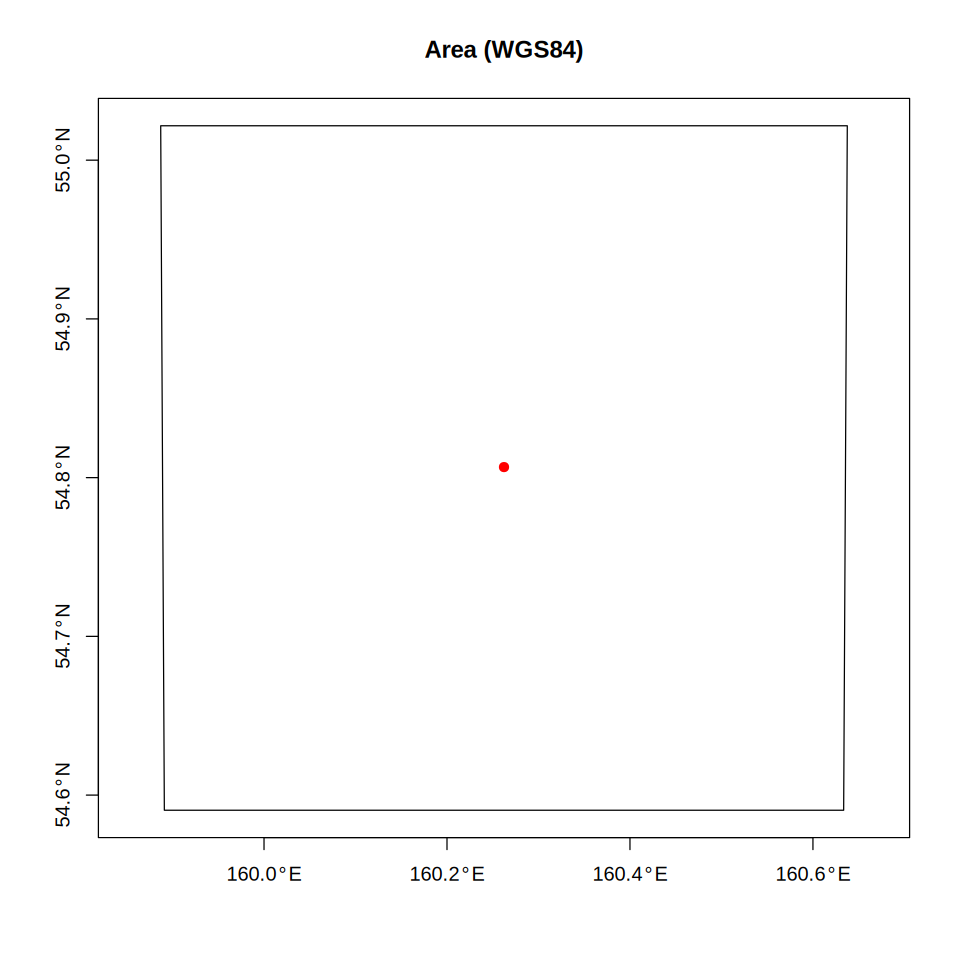

In [ ]:
aeqd <- sprintf(
  '+proj=aeqd +lat_0=%.6f +lon_0=%.6f +x_0=0 +y_0=0 +datum=WGS84 +units=m +no_defs',
  center_lat, center_lon
)

H <- half_size_km * 1000

square_aeqd <- st_as_sfc(st_bbox(c(xmin = -H, ymin = -H, xmax = H, ymax = H), crs = st_crs(aeqd)))

# area to download: square + 5% margin, in WGS84
aoi_wgs <- st_transform(st_as_sfc(st_bbox(st_buffer(square_aeqd, H * 0.05))), 4326)

plot(st_geometry(st_transform(square_aeqd, 4326)), axes = TRUE, main = 'Area (WGS84)')
points(center_lon, center_lat, pch = 19, col = 'red')

## DEM: download and resample

Mosaicing & Projecting

Clipping DEM to bbox

Note: Elevation units are in meters.



Grid: 800 x 800 | cell 60 m | zscale 20 | water: FALSE 


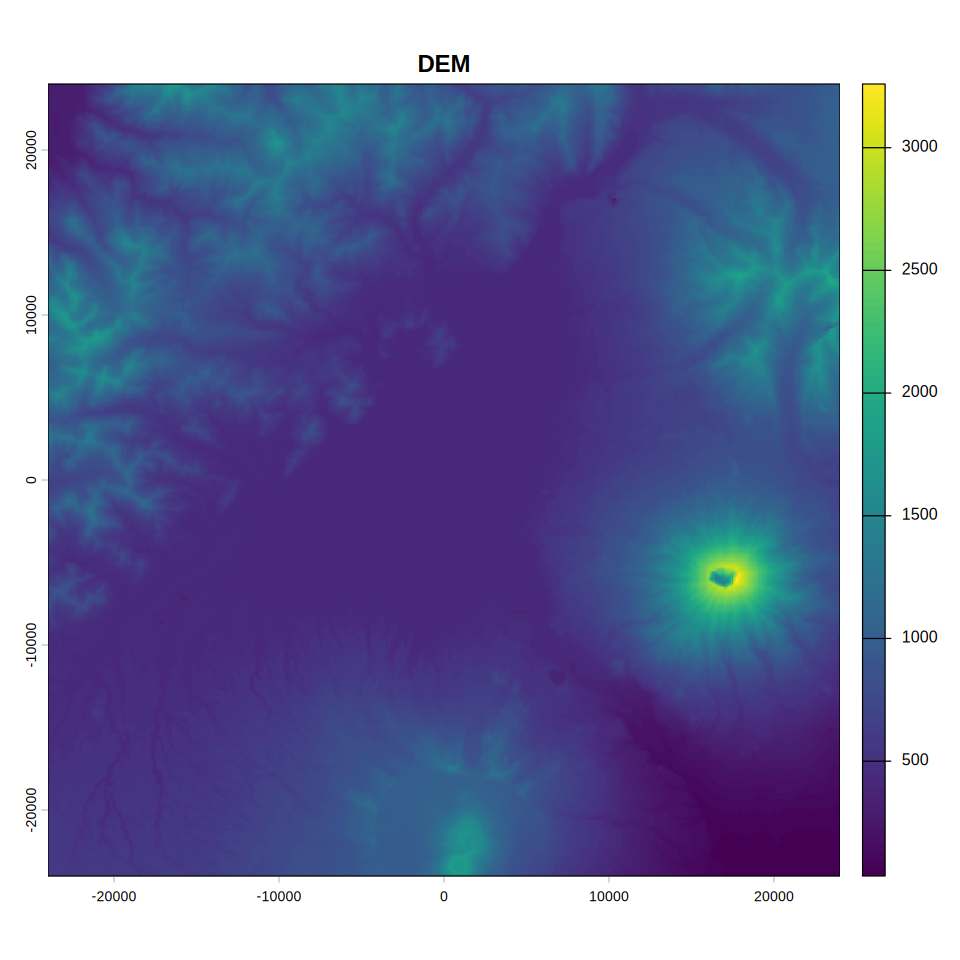

In [ ]:
dem_raw <- get_elev_raster(
  locations = st_sf(geometry = aoi_wgs),
  z = dem_zoom,
  clip = 'bbox'
)
dem_raw <- rast(dem_raw)

res_m    <- 2 * H / target_px
template <- rast(ext(-H, H, -H, H), resolution = res_m, crs = aeqd)
dem      <- project(dem_raw, template, method = 'bilinear')

elmat <- raster_to_matrix(dem)
elmat[is.na(elmat)] <- min(elmat, na.rm = TRUE)

zscale    <- res_m / exaggeration
has_water <- min(elmat) < 0   # draw the water layer only if there is terrain below sea level

cat('Grid:', ncol(elmat), 'x', nrow(elmat), '| cell', round(res_m, 1), 'm | zscale', round(zscale, 2),
    '| water:', has_water, '\n')
plot(dem, main = 'DEM')

## Shading

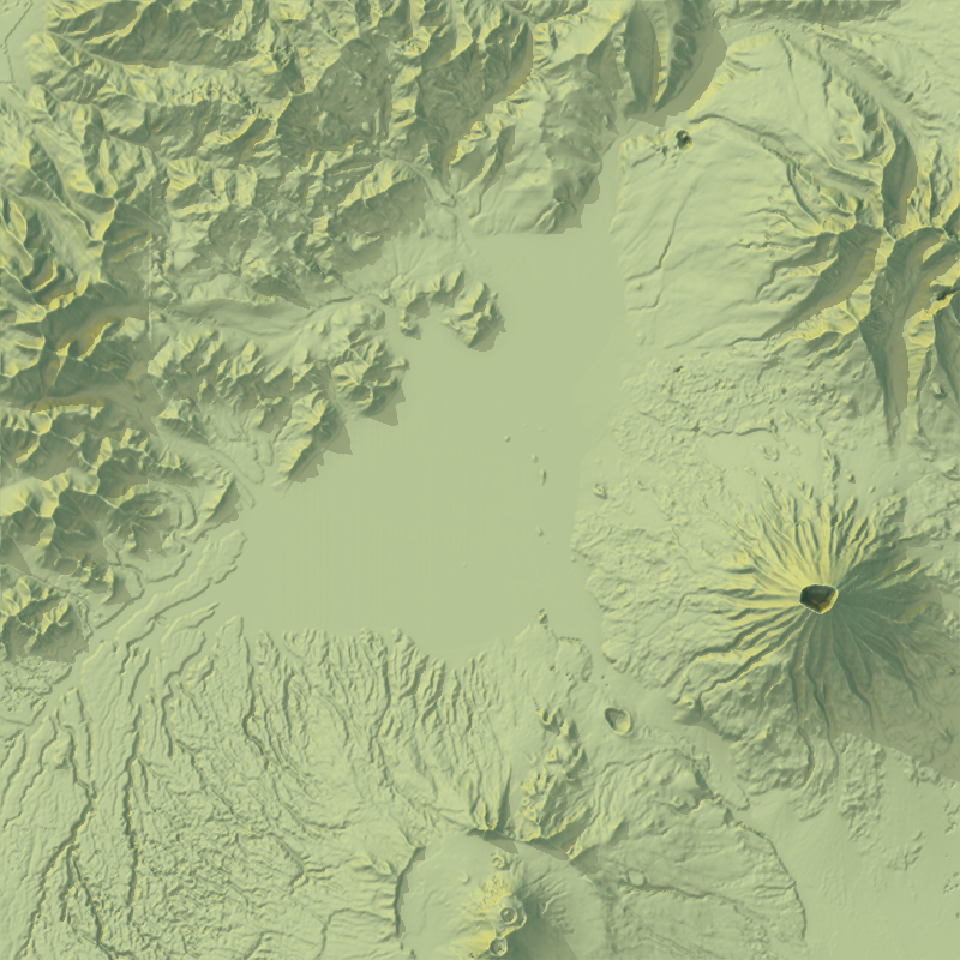

In [ ]:
shadow <- ray_shade(elmat, zscale = zscale, sunangle = 315, sunaltitude = 30)
amb    <- ambient_shade(elmat, zscale = zscale)

tex <- elmat |>
  sphere_shade(zscale = zscale, texture = 'imhof1') |>
  add_shadow(shadow, 0.5) |>
  add_shadow(amb, 0)

plot_map(tex)

## 3D hex tile

In [ ]:
tex |>
  plot_3d(
    elmat,
    zscale         = zscale,
    fov            = 0,
    theta          = theta,
    phi            = phi,
    windowsize     = c(1000, 800),
    zoom           = zoom,
    water          = has_water,
    waterdepth     = 0,
    wateralpha     = 0.5,
    watercolor     = 'lightblue',
    waterlinecolor = 'white',
    waterlinealpha = 0.5,
    baseshape      = 'hex'
  )

render_snapshot(out_snapshot)
IRdisplay::display_png(file = out_snapshot)

## Optional: high-quality render

Path tracing via `rayrender`. Takes from a minute to tens of minutes depending on `samples` and size.

In [ ]:
if (do_highquality) {
  render_highquality(
    filename    = out_highquality,
    samples     = 256,
    width       = 2000,
    height      = 1600,
    interactive = FALSE
  )
  IRdisplay::display_png(file = out_highquality)
}

In [ ]:
rgl::close3d()